In [1]:
from google.colab import files

# Step 2: Unzip the file
!unzip -q dataset.zip -d /content/extracted_files/

# Step 3: Verify the extracted contents
!ls /content/extracted_files/



dataset


In [2]:
#cell-1
import os
import random
import shutil
import timeit
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.applications import Xception
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, precision_recall_curve
from sklearn.preprocessing import label_binarize


In [3]:
#cell-2
def create_sampled_dataset(source_dir, dest_dir, sample_size_per_class):
    """
    Create a smaller dataset by sampling a fixed number of images from each class.

    Args:
        source_dir (str): Path to the source dataset directory.
        dest_dir (str): Path to save the sampled dataset.
        sample_size_per_class (int): Number of images to sample per class.
    """
    if not os.path.exists(dest_dir):
        os.makedirs(dest_dir)

    class_names = ['0', '1', '2', '3', '4']
    for class_name in class_names:
        class_dir = os.path.join(source_dir, class_name)
        sampled_class_dir = os.path.join(dest_dir, class_name)

        if not os.path.exists(sampled_class_dir):
            os.makedirs(sampled_class_dir)

        images = os.listdir(class_dir)
        random.shuffle(images)

        sampled_images = images[:sample_size_per_class]
        for img in sampled_images:
            src_path = os.path.join(class_dir, img)
            dest_path = os.path.join(sampled_class_dir, img)
            shutil.copy(src_path, dest_path)


In [4]:
#cell-3
base_dir = "/content/extracted_files/dataset"
train_source_dir = os.path.join(base_dir, "train_split")
test_source_dir = os.path.join(base_dir, "test_split")

train_dest_dir = os.path.join(base_dir, "sampled_train")
test_dest_dir = os.path.join(base_dir, "sampled_test")

# Number of images per class to sample
sample_size_per_class = 1000  # Adjust this value as needed

# Create sampled datasets
create_sampled_dataset(train_source_dir, train_dest_dir, sample_size_per_class)
create_sampled_dataset(test_source_dir, test_dest_dir, sample_size_per_class)

print("Sampled dataset created.")



Sampled dataset created.


In [6]:
# Load the trained model
model_path = "/content/xception_model (1).h5"  # Replace with your trained model's path
model = tf.keras.models.load_model(model_path, compile=False)
print("Model loaded successfully.")


Model loaded successfully.


In [7]:
# Path to the test dataset
test_data_path = "/content/extracted_files/dataset/sampled_test"  # Replace with the actual path

# Image preprocessing for testing
test_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    preprocessing_function=tf.keras.applications.xception.preprocess_input
)

target_size = (224, 224)
batch_size = 32

# Load test data
test_generator = test_datagen.flow_from_directory(
    test_data_path,
    target_size=target_size,
    batch_size=batch_size,
    class_mode="categorical",
    shuffle=False
)

# Extract true labels and class names
y_true = test_generator.classes
class_names = list(test_generator.class_indices.keys())


Found 2750 images belonging to 5 classes.


In [10]:
#cell-4
train_path = train_dest_dir
test_path = test_dest_dir

class_names = ['0', '1', '2', '3', '4']
target_size = (224, 224)
batch_size = 32

aug_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    preprocessing_function=tf.keras.applications.inception_resnet_v2.preprocess_input,
    horizontal_flip=True,
    brightness_range=[0.3, 0.8],
    width_shift_range=[-50, 0, 50, 30, -30],
    zoom_range=0.1,
    fill_mode="nearest",
)
noaug_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    preprocessing_function=tf.keras.applications.inception_resnet_v2.preprocess_input,
)

train_generator = aug_datagen.flow_from_directory(
    train_path, class_mode="categorical", target_size=target_size, shuffle=True
)
valid_generator = noaug_datagen.flow_from_directory(
    test_path, class_mode="categorical", target_size=target_size, shuffle=False,
)
y_train = train_generator.labels
y_val = valid_generator.labels

Found 3954 images belonging to 5 classes.
Found 2750 images belonging to 5 classes.


In [11]:
unique, counts = np.unique(y_train, return_counts=True)
print("Train: ", dict(zip(unique, counts)))
class_weights = compute_class_weight(
    class_weight="balanced", classes=np.unique(y_train), y=y_train
)
train_class_weights = dict(enumerate(class_weights))
print("Class Weights: ", train_class_weights)

Train:  {0: 1000, 1: 1000, 2: 1000, 3: 777, 4: 177}
Class Weights:  {0: 0.7908, 1: 0.7908, 2: 0.7908, 3: 1.0177606177606178, 4: 4.467796610169492}


In [12]:
def weighted_categorical_crossentropy(class_weights):
    def loss_fn(y_true, y_pred):
        weights = tf.reduce_sum(class_weights * y_true, axis=-1)
        unweighted_losses = tf.keras.losses.categorical_crossentropy(y_true, y_pred)
        weighted_losses = unweighted_losses * weights
        return tf.reduce_mean(weighted_losses)
    return loss_fn

# Assuming you already have the class weights as a dictionary
train_class_weights = {0: 0.7908, 1: 0.7908, 2: 0.7908, 3: 1.0177606177606178, 4: 4.467796610169492}
class_weights_array = np.array([train_class_weights[i] for i in range(len(train_class_weights))])

# Compile the model
loss_fn = weighted_categorical_crossentropy(class_weights_array)

model.compile(
    optimizer="adam",
    loss=loss_fn,
    metrics=["accuracy"]
)

In [13]:
# Evaluate the model
loss, accuracy = model.evaluate(test_generator, verbose=1)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")


/usr/local/lib/python3.10/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


86/86 ━━━━━━━━━━━━━━━━━━━━ 37s 261ms/step - accuracy: 0.7848 - loss: 0.5548
Test Loss: 0.4297
Test Accuracy: 0.8371


In [14]:
# Generate predictions
y_pred_probs = model.predict(test_generator)
y_pred = np.argmax(y_pred_probs, axis=1)

# Classification Report
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))


86/86 ━━━━━━━━━━━━━━━━━━━━ 17s 169ms/step

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.76      0.84      1000
           1       0.59      0.91      0.72       530
           2       0.93      0.80      0.86       757
           3       0.94      0.98      0.96       380
           4       0.99      1.00      0.99        83

    accuracy                           0.84      2750
   macro avg       0.88      0.89      0.87      2750
weighted avg       0.87      0.84      0.84      2750



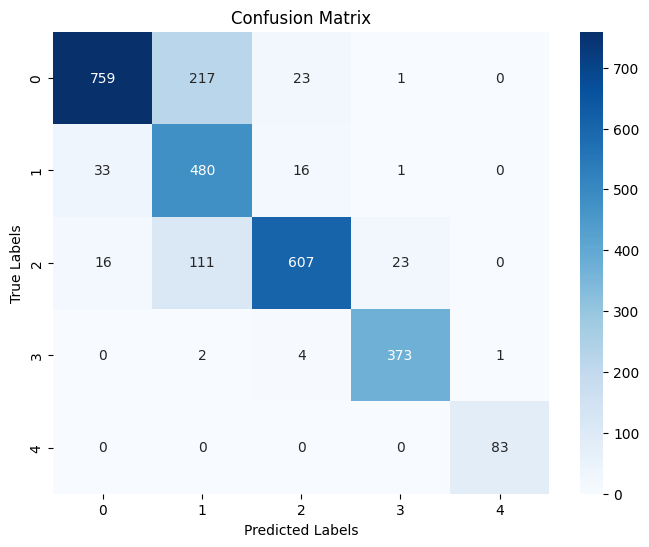

In [15]:
# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()


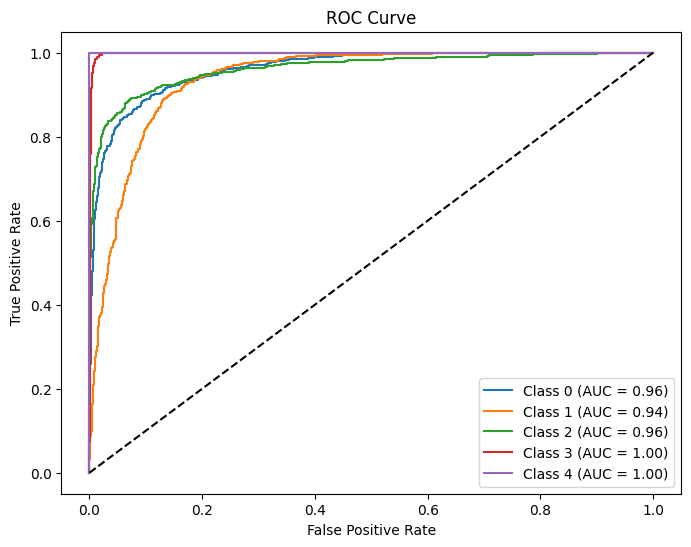

In [16]:
# Binarize true labels
y_true_bin = label_binarize(y_true, classes=[0, 1, 2, 3, 4])  # Adjust if more or fewer classes

# Compute ROC curve and AUC for each class
fpr, tpr, roc_auc = {}, {}, {}
for i in range(len(class_names)):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_pred_probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot ROC curve
plt.figure(figsize=(8, 6))
for i in range(len(class_names)):
    plt.plot(fpr[i], tpr[i], label=f"Class {class_names[i]} (AUC = {roc_auc[i]:.2f})")

plt.plot([0, 1], [0, 1], "k--")  # Diagonal line
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.show()


In [18]:
# Save metrics to a text file
with open("test_metrics.txt", "w") as file:
    file.write(f"Test Loss: {loss:.4f}\n")
    file.write(f"Test Accuracy: {accuracy:.4f}\n")
    file.write("\nClassification Report:\n")
    file.write(classification_report(y_true, y_pred, target_names=class_names))
print("Metrics saved to 'test_metrics.txt'")


Metrics saved to 'test_metrics.txt'
